# Career Prediction Case Study

### AI-Driven Intelligent Career Mapping and Skill-Based Job Role Prediction System

This notebook follows the project workflow:

**Dataset → Initial Inspection → EDA → Preprocessing → MultiLabelBinarizer → Feature Preparation → Random Forest → Evaluation → Skill Gap Analysis**

The new dataset contains education details, UG/Master's information, numerical skill scores, current skills, and the target **Job Role**.

In [2]:
# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


## 1. Load the Dataset

In [3]:
# Load Dataset

file_path = r"C:\Users\USER\Downloads\career_recommendation_dataset_current_skills_modified.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\USER\\Downloads\\career_recommendation_dataset_current_skills_modified.xlsx'

## 2. Display First 5 Rows

In [ ]:
df.head()

,Name,Education,UG Specialization,Have you completed Master's?,Master's Specialization,Programming Skill,Mathematics Aptitude,Logical Reasoning,Analytical Thinking,Problem Solving,Communication,Creativity,Teamwork,Leadership,Business Knowledge,Financial Knowledge,Design Skills,Current Skills,Job Role
0,Student_0001,Diploma,Commerce,No,NaN,75.0,48.0,82,48,53,79,40,54,49,82,20,49,"Sales, Communication, Problem Solving, Custome...",Customer Support Executive
1,Student_0002,Bachelor's,English,No,NaN,82.0,73.0,47,66,68,93,58,72,44,64,34,36,"Figma, Creativity, User Research, Design, Phot...",UI/UX Designer
2,Student_0003,Diploma,Other,Yes,MSc Physics,79.0,46.0,42,88,43,69,60,52,78,78,94,66,"Research, SQL, Machine Learning, Data Visualiz...",Data Scientist
3,Student_0004,Diploma,Other,No,NaN,51.0,35.0,41,40,85,65,69,46,78,71,35,58,"SQL, Financial Analysis, Communication, Tally,...",Accountant
4,Student_0005,Bachelor's,Economics,No,NaN,73.0,75.0,70,79,60,65,51,83,71,72,22,83,"SQL, Statistics, Python, Communication, Data V...",Data Analyst


## 3. Check Dataset Shape

In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 1508
Number of Columns: 19


## 4. Display Column Names

In [ ]:
print("Column Names:")
for column in df.columns:
    print(column)


Column Names:
Name
Education
UG Specialization
Have you completed Master's?
Master's Specialization
Programming Skill
Mathematics Aptitude
Logical Reasoning
Analytical Thinking
Problem Solving
Communication
Creativity
Teamwork
Leadership
Business Knowledge
Financial Knowledge
Design Skills
Current Skills
Job Role


## 5. Dataset Information

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1508 entries, 0 to 1507
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Name                          1508 non-null   str    
 1   Education                     1465 non-null   str    
 2   UG Specialization             1453 non-null   str    
 3   Have you completed Master's?  1485 non-null   str    
 4   Master's Specialization       587 non-null    str    
 5   Programming Skill             1466 non-null   float64
 6   Mathematics Aptitude          1466 non-null   float64
 7   Logical Reasoning             1508 non-null   int64  
 8   Analytical Thinking           1508 non-null   int64  
 9   Problem Solving               1508 non-null   int64  
 10  Communication                 1508 non-null   int64  
 11  Creativity                    1508 non-null   int64  
 12  Teamwork                      1508 non-null   int64  
 13  Leadership    

## 6. Statistical Summary

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,1508,1500,Student_0414,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,1465,3,Bachelor's,1006,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UG Specialization,1453,17,Commerce,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Have you completed Master's?,1485,2,No,874,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Master's Specialization,587,10,MA English,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Programming Skill,1466.0,NaN,NaN,NaN,63.858117,16.601174,35.0,51.0,64.0,77.0,150.0
Mathematics Aptitude,1466.0,NaN,NaN,NaN,62.858117,16.809198,-20.0,50.0,63.0,76.0,100.0
Logical Reasoning,1508.0,NaN,NaN,NaN,62.46817,15.531706,35.0,50.0,62.0,76.0,99.0
Analytical Thinking,1508.0,NaN,NaN,NaN,63.188329,15.891188,35.0,50.0,63.0,76.0,100.0
Problem Solving,1508.0,NaN,NaN,NaN,65.364721,15.430891,35.0,53.0,65.0,78.0,100.0


## 7. Check Missing Values

In [ ]:
df.isnull().sum()

Name                              0
Education                        43
UG Specialization                55
Have you completed Master's?     23
Master's Specialization         921
Programming Skill                42
Mathematics Aptitude             42
Logical Reasoning                 0
Analytical Thinking               0
Problem Solving                   0
Communication                     0
Creativity                        0
Teamwork                          0
Leadership                        0
Business Knowledge                0
Financial Knowledge               0
Design Skills                     0
Current Skills                    0
Job Role                          0
dtype: int64

In [ ]:
# ================================
# Handling Missing Values
# ================================

# 1. Categorical columns → fill with Mode

df["Education"] = df["Education"].fillna(
    df["Education"].mode()[0]
)

df["UG Specialization"] = df["UG Specialization"].fillna(
    df["UG Specialization"].mode()[0]
)

df["Have you completed Master's?"] = df["Have you completed Master's?"].fillna(
    df["Have you completed Master's?"].mode()[0]
)


# 2. Master's Specialization
# If the student has not completed Master's,
# Master's Specialization is not applicable.

df.loc[
    df["Have you completed Master's?"] == "No",
    "Master's Specialization"
] = "Not Applicable"

# If Master's is completed but specialization is missing,
# fill with the most common Master's specialization.

master_yes = df["Have you completed Master's?"] == "Yes"

master_mode = df.loc[
    master_yes, "Master's Specialization"
].mode()

if len(master_mode) > 0:
    df.loc[
        master_yes & df["Master's Specialization"].isna(),
        "Master's Specialization"
    ] = master_mode[0]


# 3. Numerical columns → fill with Median

df["Programming Skill"] = df["Programming Skill"].fillna(
    df["Programming Skill"].median()
)

df["Mathematics Aptitude"] = df["Mathematics Aptitude"].fillna(
    df["Mathematics Aptitude"].median()
)


# 4. Current Skills → fill with a meaningful text value

df["Current Skills"] = df["Current Skills"].fillna(
    "No Skills Specified"
)


# 5. Check missing values again

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Name                            0
Education                       0
UG Specialization               0
Have you completed Master's?    0
Master's Specialization         0
Programming Skill               0
Mathematics Aptitude            0
Logical Reasoning               0
Analytical Thinking             0
Problem Solving                 0
Communication                   0
Creativity                      0
Teamwork                        0
Leadership                      0
Business Knowledge              0
Financial Knowledge             0
Design Skills                   0
Current Skills                  0
Job Role                        0
dtype: int64


## 8. Check Duplicate Values

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
duplicates = df[df.duplicated(keep=False)]

duplicates

,Name,Education,UG Specialization,Have you completed Master's?,Master's Specialization,Programming Skill,Mathematics Aptitude,Logical Reasoning,Analytical Thinking,Problem Solving,Communication,Creativity,Teamwork,Leadership,Business Knowledge,Financial Knowledge,Design Skills,Current Skills,Job Role


In [ ]:
df = df.drop_duplicates()
print("Duplicates after removal:", df.duplicated().sum())

Duplicates after removal: 0


## 9. Check Unique Education Values

In [ ]:
df["Education"].unique()

<ArrowStringArray>
['Diploma', 'Bachelor's', 'Other']
Length: 3, dtype: str

## 10. Check Unique UG Specializations

In [ ]:
df["UG Specialization"].dropna().unique()

<ArrowStringArray>
[             'Commerce',               'English',                 'Other',
             'Economics',            'Electrical',            'Mechanical',
            'Psychology',                 'Hindi',      'Computer Science',
               'Physics',               'History',           'Mathematics',
           'Electronics',            'Statistics',                 'Civil',
 'Computer Applications',                  'Arts']
Length: 17, dtype: str

## 11. Check Master's Completion Values

In [ ]:
df["Have you completed Master's?"].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

## 12. Check Unique Job Roles

In [ ]:
df["Job Role"].unique()

<ArrowStringArray>
[  'Customer Support Executive',               'UI/UX Designer',
               'Data Scientist',                   'Accountant',
                 'Data Analyst',           'Teacher / Educator',
       'Database Administrator', 'Digital Marketing Specialist',
              'Sales Executive',               'Cloud Engineer',
            'Financial Analyst',             'Business Analyst',
           'Software Developer',              'Project Manager',
        'Cybersecurity Analyst',                 'HR Executive',
                'Web Developer',               'Content Writer',
               'AI/ML Engineer',             'Research Analyst']
Length: 20, dtype: str

## 13. Job Role Distribution

In [ ]:
df["Job Role"].value_counts()

Job Role
Data Scientist                  97
Cybersecurity Analyst           88
AI/ML Engineer                  86
Business Analyst                85
Database Administrator          84
Data Analyst                    83
Digital Marketing Specialist    81
Accountant                      78
Software Developer              78
HR Executive                    76
Research Analyst                74
Financial Analyst               71
Project Manager                 71
UI/UX Designer                  68
Teacher / Educator              68
Sales Executive                 68
Content Writer                  68
Customer Support Executive      62
Cloud Engineer                  62
Web Developer                   60
Name: count, dtype: int64

## 14. Check Data Types

In [ ]:
df.dtypes

Name                                str
Education                           str
UG Specialization                   str
Have you completed Master's?        str
Master's Specialization             str
Programming Skill               float64
Mathematics Aptitude            float64
Logical Reasoning                 int64
Analytical Thinking               int64
Problem Solving                   int64
Communication                     int64
Creativity                        int64
Teamwork                          int64
Leadership                        int64
Business Knowledge                int64
Financial Knowledge               int64
Design Skills                     int64
Current Skills                      str
Job Role                            str
dtype: object

# EDA (Exploratory Data Analysis)

EDA is used to understand the distribution of education, skills, current skills, and job roles before model training.

## 15. Distribution of Numerical Features

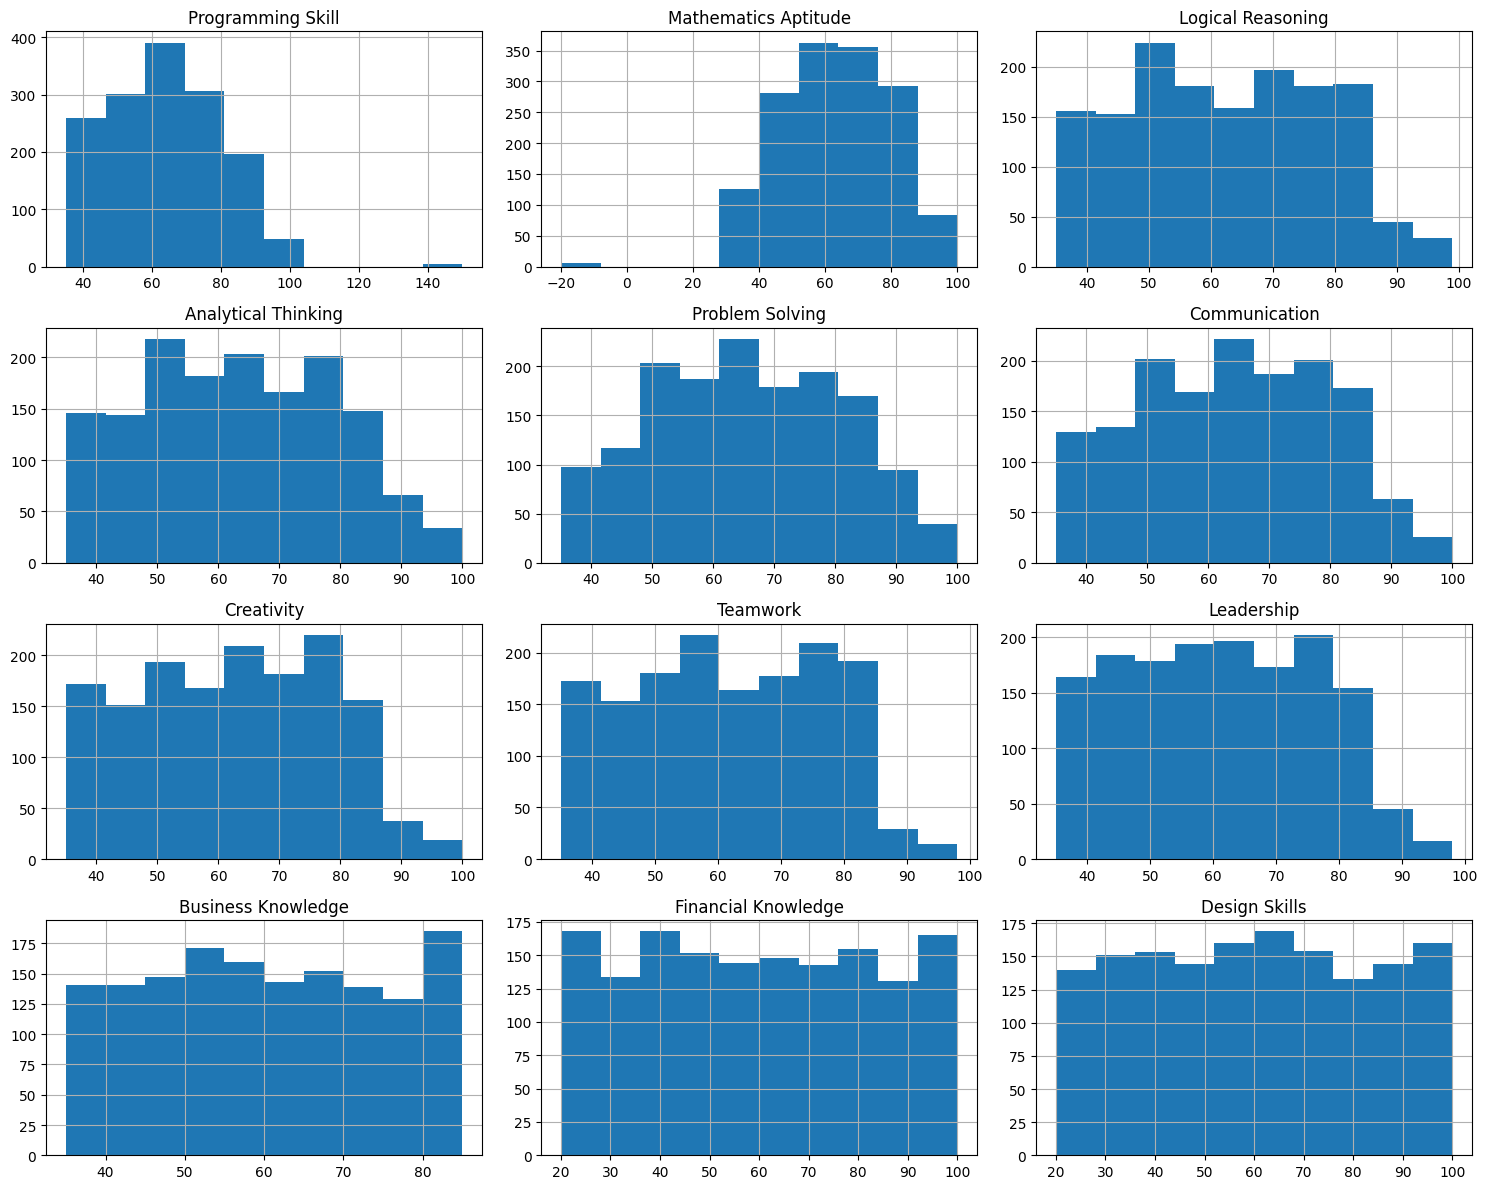

In [ ]:
numerical_features = df.select_dtypes(include=np.number).columns

df[numerical_features].hist(figsize=(15, 12), bins=10)

plt.tight_layout()
plt.show()


## 16. Education Distribution

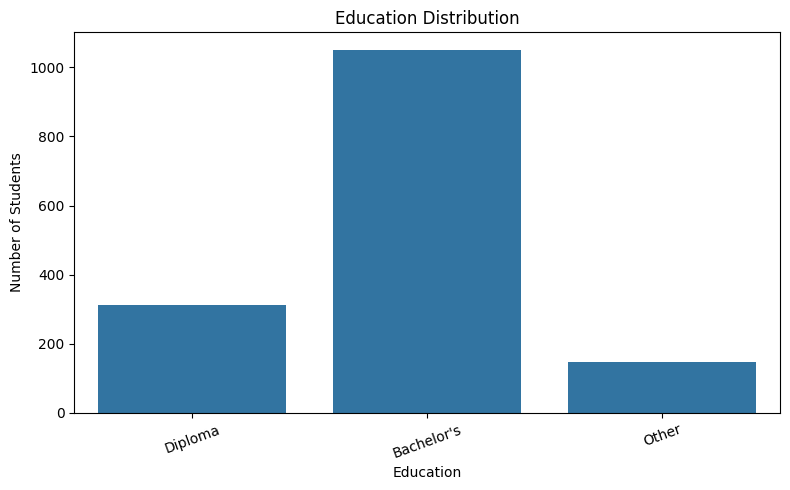

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Education")

plt.title("Education Distribution")
plt.xlabel("Education")
plt.ylabel("Number of Students")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 17. Job Role Distribution

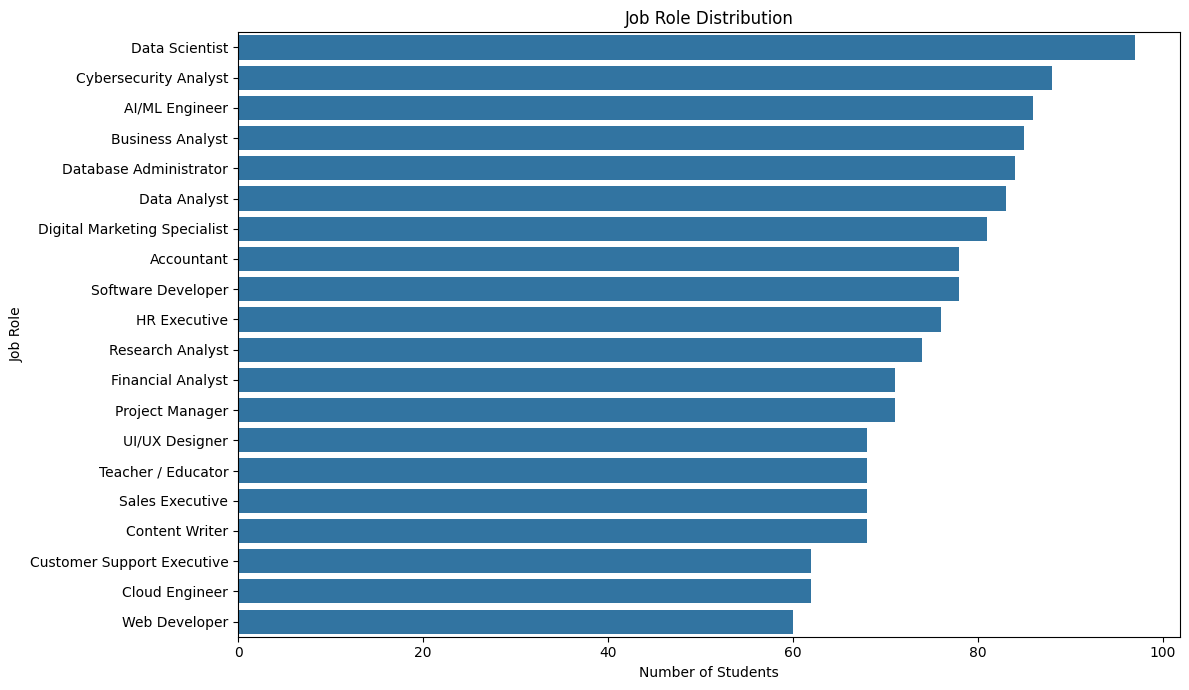

In [ ]:
plt.figure(figsize=(12, 7))
sns.countplot(data=df, y="Job Role", order=df["Job Role"].value_counts().index)

plt.title("Job Role Distribution")
plt.xlabel("Number of Students")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()


## 18. Average Skill Scores by Job Role

In [ ]:
skill_columns = [
    "Programming Skill",
    "Mathematics Aptitude",
    "Logical Reasoning",
    "Analytical Thinking",
    "Problem Solving",
    "Communication",
    "Creativity",
    "Teamwork",
    "Leadership",
    "Business Knowledge",
    "Financial Knowledge",
    "Design Skills"
]

job_role_skill_means = df.groupby("Job Role")[skill_columns].mean()

job_role_skill_means

,Programming Skill,Mathematics Aptitude,Logical Reasoning,Analytical Thinking,Problem Solving,Communication,Creativity,Teamwork,Leadership,Business Knowledge,Financial Knowledge,Design Skills
Job Role,,,,,,,,,,,,
AI/ML Engineer,70.360465,69.104651,68.116279,71.453488,76.790698,58.558140,59.860465,59.093023,63.872093,59.825581,56.418605,59.558140
Accountant,61.846154,60.871795,57.717949,62.769231,59.487179,59.884615,59.128205,59.743590,60.512821,58.846154,60.679487,58.205128
Business Analyst,58.729412,71.670588,61.070588,73.623529,67.658824,64.564706,60.741176,58.458824,59.188235,58.717647,57.564706,62.658824
Cloud Engineer,74.903226,59.032258,69.483871,59.741935,69.725806,58.193548,58.661290,61.000000,59.209677,59.645161,53.096774,61.064516
Content Writer,62.735294,57.558824,62.220588,59.808824,58.161765,67.352941,70.632353,61.191176,58.941176,57.029412,59.926471,59.926471
Customer Support Executive,58.983871,58.629032,58.854839,57.693548,60.919355,66.677419,59.580645,69.854839,71.677419,61.129032,52.306452,58.838710
Cybersecurity Analyst,71.375000,59.750000,68.306818,59.681818,67.818182,60.863636,59.477273,61.318182,61.045455,58.443182,58.034091,58.522727
Data Analyst,58.180723,71.674699,62.819277,69.638554,68.771084,62.277108,59.602410,62.301205,57.807229,60.012048,60.843373,60.072289
Data Scientist,60.525773,71.587629,58.546392,68.701031,65.020619,61.680412,61.402062,59.412371,58.865979,61.360825,59.845361,60.216495


## 19. Heatmap of Average Skill Scores by Job Role

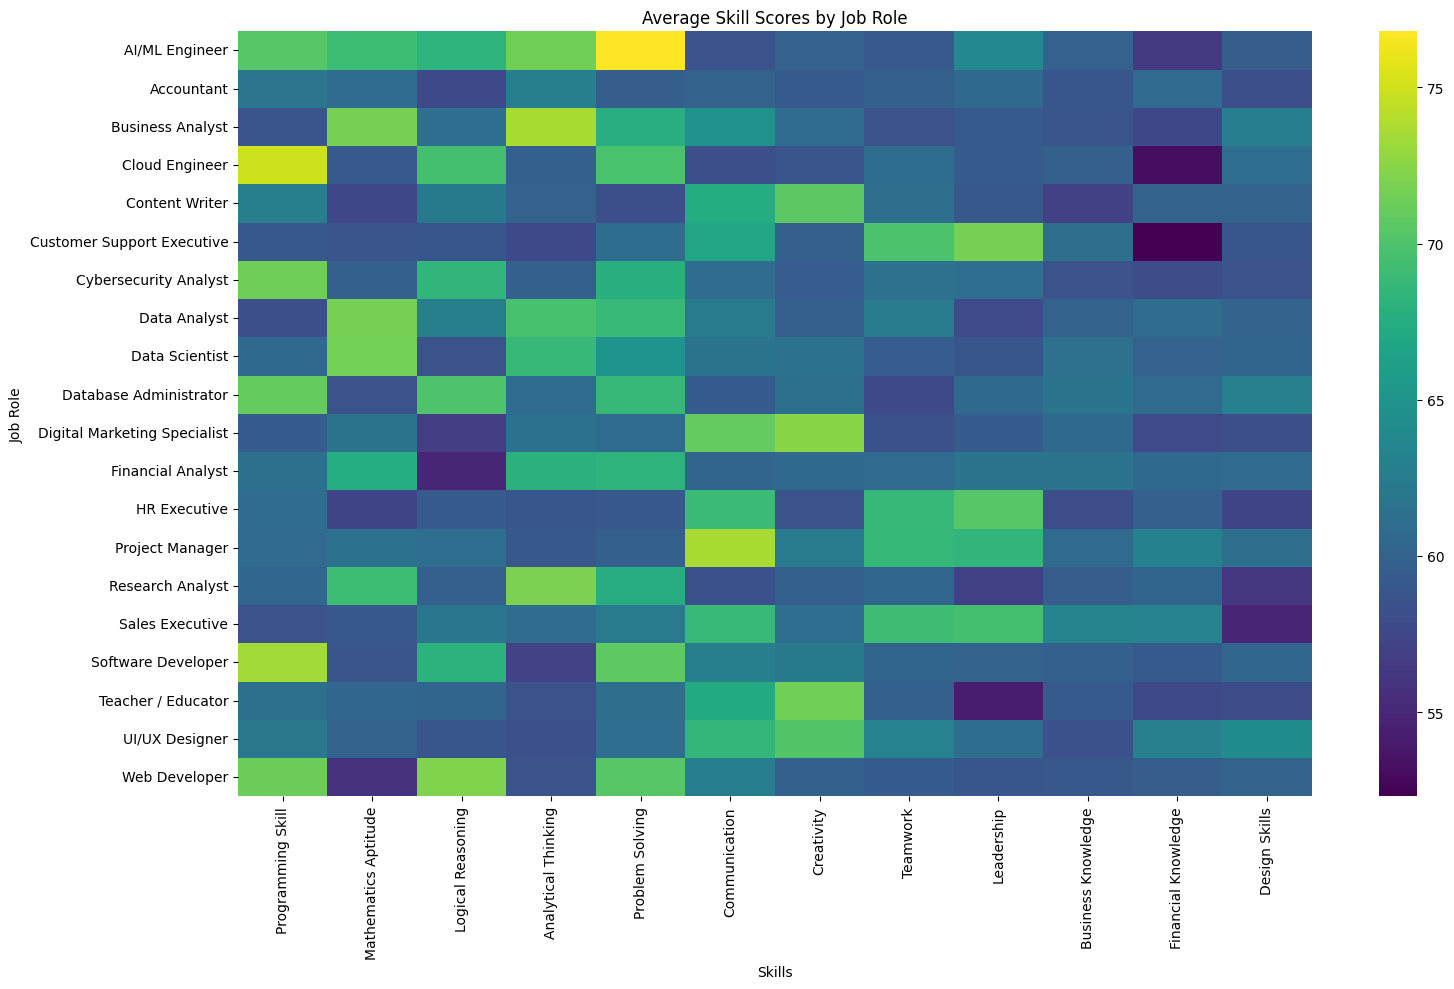

In [ ]:
plt.figure(figsize=(16, 10))
sns.heatmap(job_role_skill_means, annot=False, cmap="viridis")

plt.title("Average Skill Scores by Job Role")
plt.xlabel("Skills")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()


## 20. Programming Skill vs Job Role

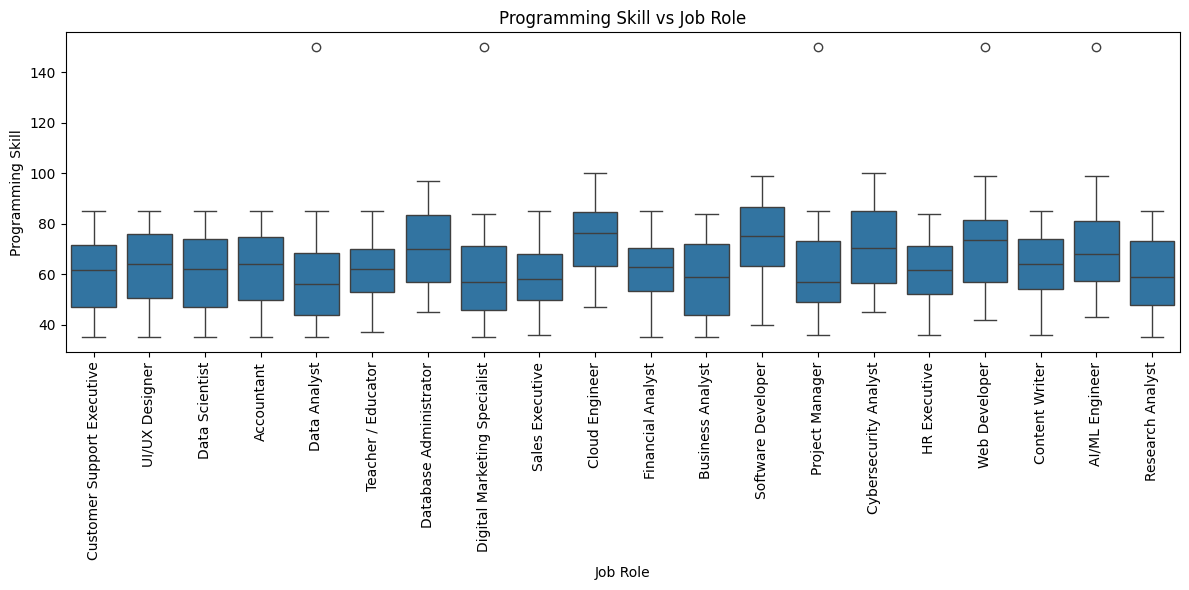

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Job Role", y="Programming Skill")

plt.xticks(rotation=90)
plt.title("Programming Skill vs Job Role")
plt.tight_layout()
plt.show()


## 21. Analytical Thinking vs Job Role

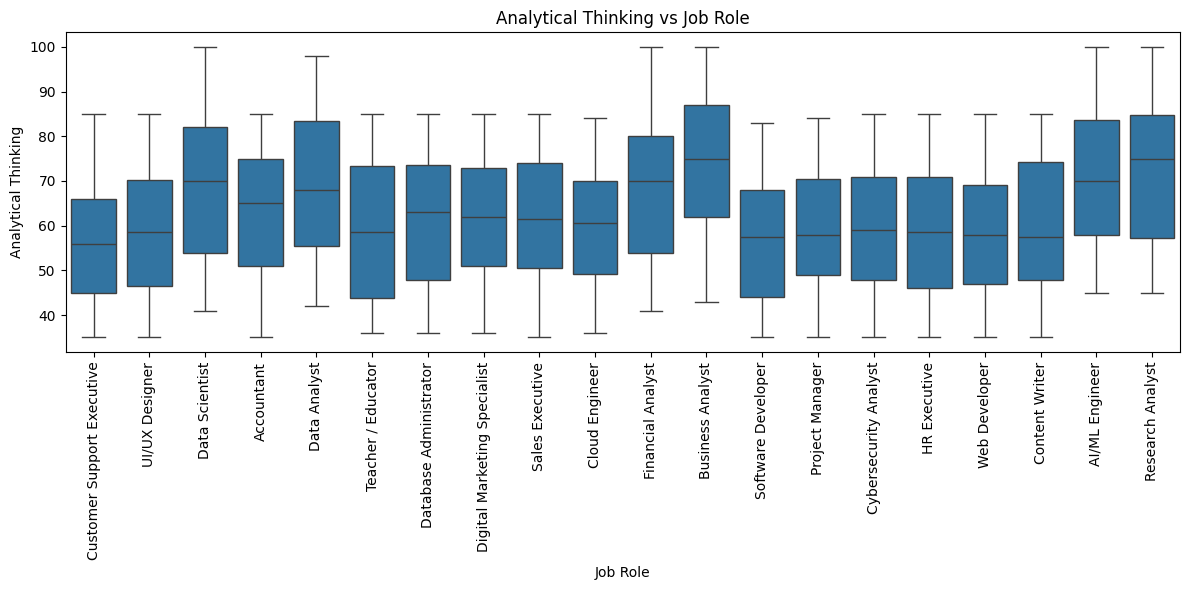

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Job Role", y="Analytical Thinking")

plt.xticks(rotation=90)
plt.title("Analytical Thinking vs Job Role")
plt.tight_layout()
plt.show()


## 22. Problem Solving vs Job Role

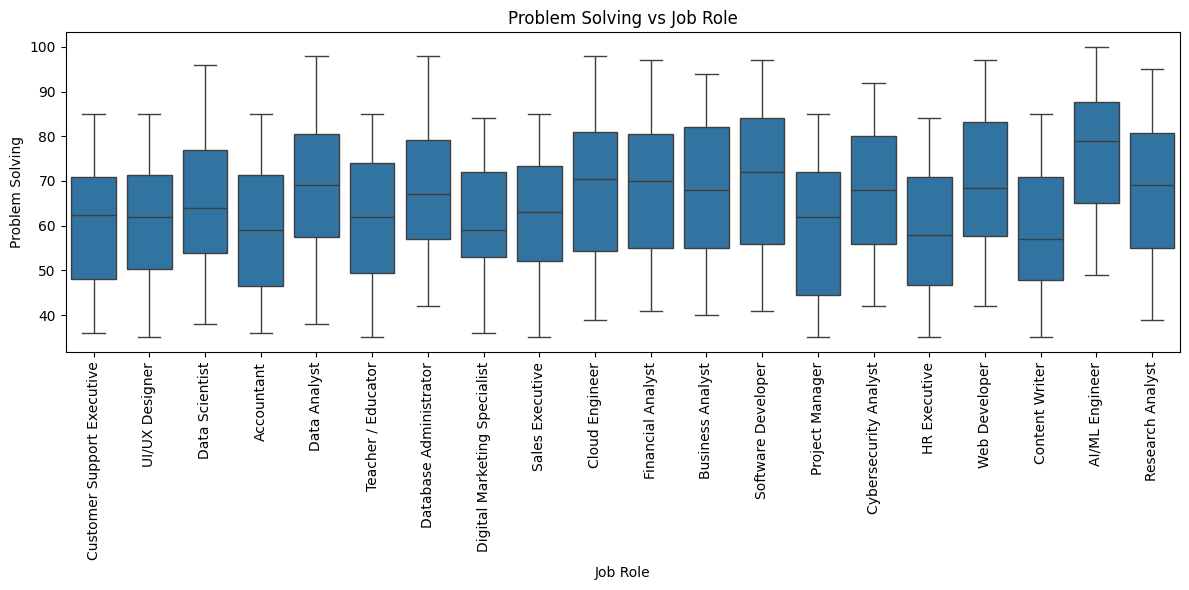

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Job Role", y="Problem Solving")

plt.xticks(rotation=90)
plt.title("Problem Solving vs Job Role")
plt.tight_layout()
plt.show()


# Data Preprocessing

Before model training, we will:

1. Remove the `Name` column.
2. Handle missing values.
3. Remove duplicate records.
4. Convert categorical information into numerical features.
5. Use **MultiLabelBinarizer** for `Current Skills`.
6. Encode the target `Job Role`.


## 23. Remove Duplicate Records

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)


Shape after removing duplicates: (1508, 19)


## 24. Remove Name Column

In [ ]:
df = df.drop(columns=["Name"])

print("Name column removed.")
print("Current shape:", df.shape)


Name column removed.
Current shape: (1508, 18)


## 25. Handle Missing Values

In [ ]:
# Fill categorical columns

categorical_columns = [
    "Education",
    "UG Specialization",
    "Have you completed Master's?",
    "Master's Specialization"
]

for column in categorical_columns:
    df[column] = df[column].fillna("Unknown")

# Fill numerical skill columns with median

for column in skill_columns[:-1]:
    df[column] = df[column].fillna(df[column].median())

# Current Skills is text, so use a placeholder
df["Current Skills"] = df["Current Skills"].fillna("No Skills Specified")

print("Missing values after preprocessing:")
print(df.isnull().sum())


Missing values after preprocessing:
Education                       0
UG Specialization               0
Have you completed Master's?    0
Master's Specialization         0
Programming Skill               0
Mathematics Aptitude            0
Logical Reasoning               0
Analytical Thinking             0
Problem Solving                 0
Communication                   0
Creativity                      0
Teamwork                        0
Leadership                      0
Business Knowledge              0
Financial Knowledge             0
Design Skills                   0
Current Skills                  0
Job Role                        0
dtype: int64


## 26. Prepare Current Skills for MultiLabelBinarizer

`Current Skills` contains multiple skills in one cell, for example:

`Python, SQL, Excel, Machine Learning`

Since one student can have **multiple skills**, MultiLabelBinarizer converts the list into separate binary columns.

In [ ]:
# Convert Current Skills text into lists

skill_lists = df["Current Skills"].apply(
    lambda x: [skill.strip() for skill in str(x).split(",")]
)

skill_lists.head()


0    [Sales, Communication, Problem Solving, Custom...
1    [Figma, Creativity, User Research, Design, Pho...
2    [Research, SQL, Machine Learning, Data Visuali...
3    [SQL, Financial Analysis, Communication, Tally...
4    [SQL, Statistics, Python, Communication, Data ...
Name: Current Skills, dtype: object

## 27. Apply MultiLabelBinarizer

In [ ]:
# Convert Current Skills into a list of individual skills

skill_lists = df["Current Skills"].apply(
    lambda x: [skill.strip() for skill in str(x).split(",")]
)

skill_lists.head()

0    [Sales, Communication, Problem Solving, Custom...
1    [Figma, Creativity, User Research, Design, Pho...
2    [Research, SQL, Machine Learning, Data Visuali...
3    [SQL, Financial Analysis, Communication, Tally...
4    [SQL, Statistics, Python, Communication, Data ...
Name: Current Skills, dtype: object

In [ ]:
mlb = MultiLabelBinarizer()

current_skills_encoded = mlb.fit_transform(skill_lists)

current_skills_df = pd.DataFrame(
    current_skills_encoded,
    columns=[f"Skill_{skill}" for skill in mlb.classes_],
    index=df.index
)

print("Number of Current Skill features:", current_skills_df.shape[1])
current_skills_df.head()


Number of Current Skill features: 53


,Skill_Accounting,Skill_Analytics,Skill_Business Analysis,Skill_CRM,Skill_Cloud,Skill_Communication,Skill_Conflict Management,Skill_Content Writing,Skill_Creativity,Skill_Cryptography,...,Skill_Statistics,Skill_Tally,Skill_Taxation,Skill_Teaching,Skill_Team Management,Skill_TensorFlow,Skill_User Research,Skill_Web Development,Skill_WordPress,Skill_Writing
0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


## 28. Remove Original Current Skills Column

In [ ]:
#Remove the original text column because its information has already been converted into current_skills_df.

df_model = df.drop(columns=["Current Skills"])

print(df_model.shape)


(1508, 17)


## 29. Encode Categorical Input Features

The model cannot directly use text values such as `Bachelor's`, `Commerce`, `Yes`, or `MBA`.

We will convert these categorical columns into numerical dummy variables.

In [ ]:
categorical_input_columns = [
    "Education",
    "UG Specialization",
    "Have you completed Master's?",
    "Master's Specialization"
]

df_model = pd.get_dummies(
    df_model,
    columns=categorical_input_columns,
    dtype=int
)

df_model.head()


,Programming Skill,Mathematics Aptitude,Logical Reasoning,Analytical Thinking,Problem Solving,Communication,Creativity,Teamwork,Leadership,Business Knowledge,...,Master's Specialization_MA History,Master's Specialization_MBA,Master's Specialization_MCA,Master's Specialization_MCom,Master's Specialization_MSc Computer Science,Master's Specialization_MSc Data Science,Master's Specialization_MSc Mathematics,Master's Specialization_MSc Physics,Master's Specialization_MSc Statistics,Master's Specialization_Not Applicable
0,75.0,48.0,82,48,53,79,40,54,49,82,...,0,0,0,0,0,0,0,0,0,1
1,82.0,73.0,47,66,68,93,58,72,44,64,...,0,0,0,0,0,0,0,0,0,1
2,79.0,46.0,42,88,43,69,60,52,78,78,...,0,0,0,0,0,0,0,1,0,0
3,51.0,35.0,41,40,85,65,69,46,78,71,...,0,0,0,0,0,0,0,0,0,1
4,73.0,75.0,70,79,60,65,51,83,71,72,...,0,0,0,0,0,0,0,0,0,1


## 30. Combine MultiLabelBinarizer Features

In [ ]:
X = pd.concat(
    [
        df_model.drop(columns=["Job Role"]),
        current_skills_df
    ],
    axis=1
)

print("Feature matrix shape:", X.shape)
X.head()


Feature matrix shape: (1508, 98)


,Programming Skill,Mathematics Aptitude,Logical Reasoning,Analytical Thinking,Problem Solving,Communication,Creativity,Teamwork,Leadership,Business Knowledge,...,Skill_Statistics,Skill_Tally,Skill_Taxation,Skill_Teaching,Skill_Team Management,Skill_TensorFlow,Skill_User Research,Skill_Web Development,Skill_WordPress,Skill_Writing
0,75.0,48.0,82,48,53,79,40,54,49,82,...,0,0,0,0,0,0,0,0,0,0
1,82.0,73.0,47,66,68,93,58,72,44,64,...,0,0,0,0,0,0,1,0,0,0
2,79.0,46.0,42,88,43,69,60,52,78,78,...,1,0,0,0,0,0,0,0,0,0
3,51.0,35.0,41,40,85,65,69,46,78,71,...,0,1,0,0,0,0,0,0,0,0
4,73.0,75.0,70,79,60,65,51,83,71,72,...,1,0,0,0,0,0,0,0,0,0


## 31. Encode Target Variable

In [ ]:
job_role_encoder = LabelEncoder()

y = job_role_encoder.fit_transform(df_model["Job Role"])

print("Target shape:", y.shape)
print("Number of Job Roles:", len(job_role_encoder.classes_))
print("Job Roles:")
print(job_role_encoder.classes_)


Target shape: (1508,)
Number of Job Roles: 20
Job Roles:
['AI/ML Engineer' 'Accountant' 'Business Analyst' 'Cloud Engineer'
 'Content Writer' 'Customer Support Executive' 'Cybersecurity Analyst'
 'Data Analyst' 'Data Scientist' 'Database Administrator'
 'Digital Marketing Specialist' 'Financial Analyst' 'HR Executive'
 'Project Manager' 'Research Analyst' 'Sales Executive'
 'Software Developer' 'Teacher / Educator' 'UI/UX Designer'
 'Web Developer']


## 32. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (1206, 98)
X_test : (302, 98)
y_train: (1206,)
y_test : (302,)


## 33. Train Random Forest Model

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


NameError: name 'RandomForestClassifier' is not defined

In [ ]:
import joblib

# Save the trained model and preprocessing objects
model_bundle = {
    "model": rf_model,
    "mlb": mlb,
    "job_role_encoder": job_role_encoder,
    "feature_columns": X.columns.tolist()
}

joblib.dump(model_bundle, "career_model.pkl")

print("Model saved successfully!")
print("File: career_model.pkl")

## 34. Model Evaluation

In [ ]:
y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=job_role_encoder.classes_
    )
)


Accuracy: 0.9801324503311258

Classification Report:
                              precision    recall  f1-score   support

              AI/ML Engineer       1.00      0.82      0.90        17
                  Accountant       1.00      1.00      1.00        16
            Business Analyst       1.00      1.00      1.00        17
              Cloud Engineer       1.00      1.00      1.00        12
              Content Writer       1.00      1.00      1.00        14
  Customer Support Executive       1.00      1.00      1.00        12
       Cybersecurity Analyst       1.00      1.00      1.00        18
                Data Analyst       0.89      1.00      0.94        17
              Data Scientist       0.84      0.84      0.84        19
      Database Administrator       1.00      1.00      1.00        17
Digital Marketing Specialist       1.00      1.00      1.00        16
           Financial Analyst       1.00      1.00      1.00        14
                HR Executive       1

In [ ]:
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=job_role_encoder.classes_,
    columns=job_role_encoder.classes_
)

cm_df

,AI/ML Engineer,Accountant,Business Analyst,Cloud Engineer,Content Writer,Customer Support Executive,Cybersecurity Analyst,Data Analyst,Data Scientist,Database Administrator,Digital Marketing Specialist,Financial Analyst,HR Executive,Project Manager,Research Analyst,Sales Executive,Software Developer,Teacher / Educator,UI/UX Designer,Web Developer
AI/ML Engineer,14,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0
Accountant,0,16,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Business Analyst,0,0,17,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Cloud Engineer,0,0,0,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Content Writer,0,0,0,0,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Customer Support Executive,0,0,0,0,0,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Cybersecurity Analyst,0,0,0,0,0,0,18,0,0,0,0,0,0,0,0,0,0,0,0,0
Data Analyst,0,0,0,0,0,0,0,17,0,0,0,0,0,0,0,0,0,0,0,0
Data Scientist,0,0,0,0,0,0,0,2,16,0,0,0,0,0,1,0,0,0,0,0
Database Administrator,0,0,0,0,0,0,0,0,0,17,0,0,0,0,0,0,0,0,0,0


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
55,Skill_Customer Service,0.036592
65,Skill_Financial Analysis,0.033693
80,Skill_Python,0.030487
66,Skill_Git,0.029174
88,Skill_Statistics,0.029139
78,Skill_Problem Solving,0.028626
81,Skill_Recruitment,0.026780
85,Skill_SQL,0.026653
75,Skill_Networking,0.025738
82,Skill_Research,0.024745


## 35. Confusion Matrix

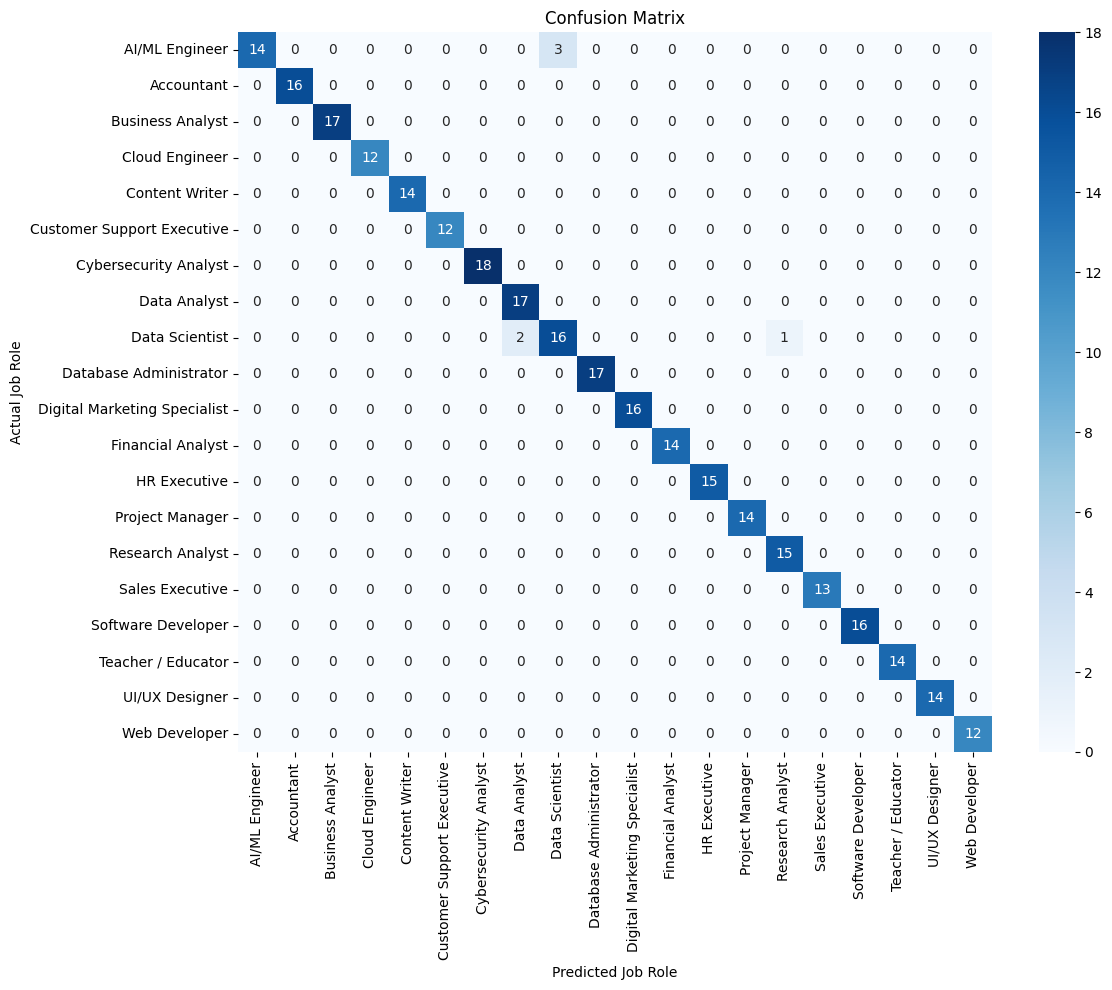

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=job_role_encoder.classes_,
    yticklabels=job_role_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Job Role")
plt.ylabel("Actual Job Role")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 20 features
feature_importance.head(20)

,Feature,Importance
55,Skill_Customer Service,0.036592
65,Skill_Financial Analysis,0.033693
80,Skill_Python,0.030487
66,Skill_Git,0.029174
88,Skill_Statistics,0.029139
78,Skill_Problem Solving,0.028626
81,Skill_Recruitment,0.026780
85,Skill_SQL,0.026653
75,Skill_Networking,0.025738
82,Skill_Research,0.024745


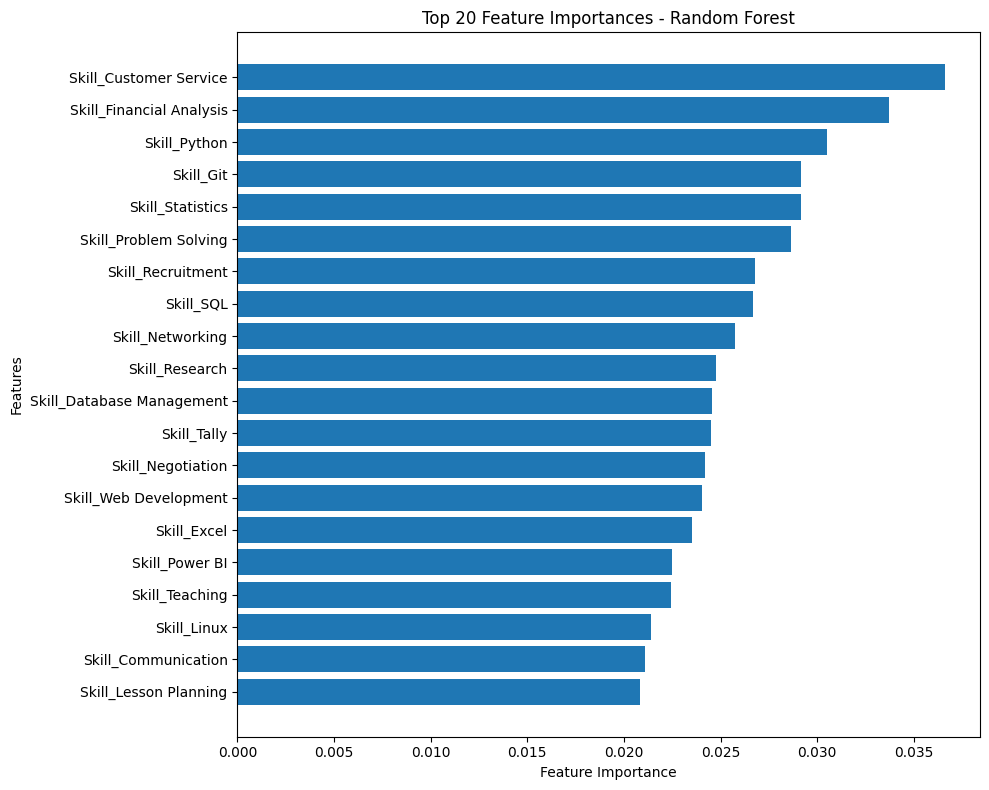

In [ ]:
plt.figure(figsize=(10, 8))

top_features = feature_importance.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 20 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
# Compare Actual and Predicted Job Roles

comparison = pd.DataFrame({
    "Actual Job Role": job_role_encoder.inverse_transform(y_test),
    "Predicted Job Role": job_role_encoder.inverse_transform(y_pred)
})

comparison.head(20)

,Actual Job Role,Predicted Job Role
0,Data Analyst,Data Analyst
1,Project Manager,Project Manager
2,Accountant,Accountant
3,Financial Analyst,Financial Analyst
4,UI/UX Designer,UI/UX Designer
5,Research Analyst,Research Analyst
6,Teacher / Educator,Teacher / Educator
7,Cybersecurity Analyst,Cybersecurity Analyst
8,UI/UX Designer,UI/UX Designer
9,Research Analyst,Research Analyst


# Skill Gap Analysis

After predicting a job role, the student's skill scores can be compared with the average skill profile of that predicted role.

A skill gap is identified when the student's score is below the corresponding average score for the predicted role.

In [ ]:
# Required skills for each job role

required_skills = {
    "AI/ML Engineer": ["Python", "Machine Learning", "Statistics", "Git", "Data Visualization"],
    "Accountant": ["Accounting", "Tally", "Excel", "Financial Analysis"],
    "Business Analyst": ["SQL", "Excel", "Business Analysis", "Data Visualization"],
    "Cloud Engineer": ["Cloud", "Linux", "Networking", "Git"],
    "Content Writer": ["Writing", "Communication", "Research", "Creativity"],
    "Customer Support Executive": ["Customer Service", "Communication", "Problem Solving"],
    "Cybersecurity Analyst": ["Cybersecurity", "Linux", "Networking", "Python"],
    "Data Analyst": ["Python", "SQL", "Excel", "Power BI", "Statistics"],
    "Data Scientist": ["Python", "Machine Learning", "Statistics", "SQL", "Data Visualization"],
    "Database Administrator": ["SQL", "Database Management", "Linux", "Networking"],
    "Digital Marketing Specialist": ["Digital Marketing", "SEO", "Social Media", "Communication"],
    "Financial Analyst": ["Financial Analysis", "Excel", "Statistics", "Power BI"],
    "HR Executive": ["Recruitment", "Communication", "Leadership", "Customer Service"],
    "Project Manager": ["Project Management", "Leadership", "Communication", "Problem Solving"],
    "Research Analyst": ["Research", "Statistics", "Python", "Excel"],
    "Sales Executive": ["Sales", "Communication", "Negotiation", "Customer Service"],
    "Software Developer": ["Python", "Java", "Git", "Problem Solving", "SQL"],
    "Teacher / Educator": ["Teaching", "Lesson Planning", "Communication", "Writing"],
    "UI/UX Designer": ["Figma", "Photoshop", "Creativity", "Design"],
    "Web Developer": ["HTML/CSS", "JavaScript", "Git", "Web Development"]
}

print("Required skills defined for", len(required_skills), "job roles.")

Required skills defined for 20 job roles.


In [ ]:
def skill_gap_analysis(predicted_role, current_skills):
    required = set(required_skills[predicted_role])
    current = set(current_skills)

    matched_skills = required.intersection(current)
    missing_skills = required.difference(current)

    print("Predicted Job Role:", predicted_role)

    print("\nRequired Skills:")
    print(", ".join(sorted(required)))

    print("\nMatched Skills:")
    print(", ".join(sorted(matched_skills)) if matched_skills else "None")

    print("\nSkill Gap / Missing Skills:")
    print(", ".join(sorted(missing_skills)) if missing_skills else "No major skill gap")

    return missing_skills

In [ ]:
predicted_role = "Data Analyst"

student_skills = ["Python", "Excel", "Communication"]

skill_gap_analysis(predicted_role, student_skills)

Predicted Job Role: Data Analyst

Required Skills:
Excel, Power BI, Python, SQL, Statistics

Matched Skills:
Excel, Python

Skill Gap / Missing Skills:
Power BI, SQL, Statistics


{'Power BI', 'SQL', 'Statistics'}

In [ ]:
import joblib

joblib.dump(rf_model, "career_random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [ ]:
import joblib

# Save the trained model
joblib.dump(rf_model, "career_random_forest.pkl")

# Save preprocessing objects
joblib.dump(mlb, "current_skills_mlb.pkl")
joblib.dump(job_role_encoder, "job_role_encoder.pkl")

# Save the exact feature-column order used during training
joblib.dump(X.columns.tolist(), "model_features.pkl")

print("Model and preprocessing objects saved successfully!")

Model and preprocessing objects saved successfully!


In [ ]:
import os

files = [
    "career_random_forest.pkl",
    "current_skills_mlb.pkl",
    "job_role_encoder.pkl",
    "model_features.pkl"
]

for file in files:
    if os.path.exists(file):
        print("✅", file)
    else:
        print("❌", file, "not found")

✅ career_random_forest.pkl
✅ current_skills_mlb.pkl
✅ job_role_encoder.pkl
✅ model_features.pkl
